# Bài thực hành số 3 — Trích chọn đặc trưng và học từ dữ liệu IoT

**Họ và tên:** ……………………  **Mã sinh viên:** ……………  **Lớp/nhóm:** ……………  **Ngày thực hành:** ……………

Kế thừa từ dự án Bài 1 + Bài 2 trong repo này:

| Thành phần | Trong dự án | Vai trò ở Bài 3 |
|---|---|---|
| Nút cảm biến | ESP32 DevKit V1 trên Wokwi (`src/main.cpp`, `diagram.json`): DHT22 DATA = GPIO15 | `temperature` (°C), `humidity` (%RH) — 2 kênh chuỗi thời gian |
| Khoảng cách | HC-SR04 TRIG = GPIO5, ECHO = GPIO18; LED gửi = GPIO2, LED cảnh báo = GPIO4 | `distance_cm` (cm) — kênh thứ 3 |
| Truyền dữ liệu | Wi-Fi Wokwi-GUEST → MQTT `broker.emqx.io` → bridge → Mosquitto local, topic `<namespace>/iot/sensor/room1`, chu kỳ 5 s | Giữ nguyên chu kỳ 5 s, không sửa firmware |
| Telemetry | `temperature, humidity, distance_cm, seq, ts, uptime_s, rssi, alarm` | 3 kênh vật lý tạo X; `seq`/`uptime_s` chỉ dùng phát hiện reset, `rssi` kiểm tra kết nối |
| Lưu trữ (Bài 2) | `server/collector.py` → MongoDB time-series `sensor_raw`; `preprocess.py` → `sensor_processed` | Xuất `du_lieu_B2.csv` từ `sensor_raw` bằng `server/export_b2_csv.py` (còn đơn vị vật lý, chưa chuẩn hoá) |
| Hiển thị | Streamlit `server/dashboard.py` | Thêm tab dự báo `temperature_forecast_next60s` (`server/forecast_b3.py`) |

Ghi chú tên cột: firmware gửi `seq`, CSV bàn giao đổi thành `sequence` theo schema của đề.

In [1]:
# Ô 1 — Thư viện và khai báo nguồn dữ liệu
import json
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Chạy thử bằng bộ mẫu; khi có dữ liệu nhóm đổi sang "du_lieu_B2.csv"
# (xuất bằng: cd server && python export_b2_csv.py --device esp32-room1 --minutes 60)
DATA_PATH = "du_lieu_mau_B2.csv"
TIME_FORMAT = "ms"          # "ms" = Unix milliseconds, "iso" = ISO8601 có múi giờ
# Khi đổi sang du_lieu_B2.csv: sửa DATA_NOTE (Wokwi -> MQTT -> MongoDB, phiên thu, thao tác đã làm trên Wokwi)
DATA_NOTE = ("Bộ mẫu tạo bằng Python (bai3/tao_du_lieu_mau.py, seed=3), 720 dòng = 60 phút, chu kỳ 5 s, "
             "theo schema kế thừa Bài 2. KHÔNG phải dữ liệu tải từ ThingsBoard/MongoDB. "
             "Dùng để kiểm tra quy trình khi chưa xuất được du_lieu_B2.csv của nhóm.")
TZ = "Asia/Ho_Chi_Minh"
SAMPLE_S = 5
SENSORS = ["temperature", "humidity", "distance_cm"]
UNITS = {"temperature": "°C", "humidity": "%RH", "distance_cm": "cm"}
VALID_RANGE = {"temperature": (-40, 80), "humidity": (0, 100), "distance_cm": (2, 400)}
OUT_DIR = Path("ket_qua_B3")
OUT_DIR.mkdir(exist_ok=True)
# Không đặt token MQTT, API key, JWT hay MONGO_URI có mật khẩu trong notebook nộp.
print("DATA_PATH =", DATA_PATH, "| TIME_FORMAT =", TIME_FORMAT)
print(DATA_NOTE)

DATA_PATH = du_lieu_mau_B2.csv | TIME_FORMAT = ms
Bộ mẫu tạo bằng Python (bai3/tao_du_lieu_mau.py, seed=3), 720 dòng = 60 phút, chu kỳ 5 s, theo schema kế thừa Bài 2. KHÔNG phải dữ liệu tải từ ThingsBoard/MongoDB. Dùng để kiểm tra quy trình khi chưa xuất được du_lieu_B2.csv của nhóm.


## IV. Tiếp nhận chuỗi dữ liệu IoT

In [2]:
# Ô 2 — Kiểm tra tên cột, thời gian, thiết bị, trùng, thiếu, miền hợp lệ
raw = pd.read_csv(DATA_PATH)
missing_cols = [c for c in ["timestamp", *SENSORS] if c not in raw.columns]
assert not missing_cols, f"Thiếu cột bắt buộc: {missing_cols}"
n_rows_in = len(raw)

if TIME_FORMAT == "ms":
    raw["ts"] = pd.to_datetime(raw["timestamp"].astype("int64"), unit="ms", utc=True)
else:
    raw["ts"] = pd.to_datetime(raw["timestamp"], utc=True)   # chuỗi ISO phải có múi giờ

# Cột khuyến nghị: nếu thiếu thì đặt tên dự phòng và ghi lại
fallback = []
for col, val in [("device_id", "thiet_bi_du_phong"), ("session_id", "phien_du_phong"),
                 ("data_source", "khong_ro")]:
    if col not in raw.columns:
        raw[col] = val
        fallback.append(col)
if "temperature_observed" not in raw.columns:
    # Chỉ hợp lệ khi chắc chắn Bài 2 KHÔNG bù nhiệt độ trong tệp xuất
    raw["temperature_observed"] = 1
    fallback.append("temperature_observed")

devices = raw["device_id"].dropna().unique()
assert len(devices) == 1, f"Tệp phải thuộc một thiết bị, đang có: {devices}"
for c in SENSORS:
    raw[c] = pd.to_numeric(raw[c], errors="coerce")

n_dup = int(raw.duplicated(subset=["device_id", "ts"]).sum())
df = raw.drop_duplicates(subset=["device_id", "ts"]).sort_values("ts").reset_index(drop=True)
missing_before = df[SENSORS].isna().sum()
out_of_range = {}
for c, (lo, hi) in VALID_RANGE.items():
    bad = df[c].notna() & ~df[c].between(lo, hi)
    out_of_range[c] = int(bad.sum())
    df.loc[bad, c] = np.nan            # ngoài miền -> thiếu, không xoá cả dòng
missing_after = df[SENSORS].isna().sum()
# Nhãn y chỉ dùng nhiệt độ quan sát gốc
df["temperature_label"] = df["temperature"].where(df["temperature_observed"] == 1)

interval = df["ts"].diff().dt.total_seconds()
check = pd.DataFrame({"đơn vị": UNITS, "thiếu ban đầu": missing_before,
                      "ngoài miền -> thiếu": out_of_range, "thiếu sau kiểm tra": missing_after,
                      "min": df[SENSORS].min().round(2), "max": df[SENSORS].max().round(2)})
print(f"Thiết bị: {devices[0]} | nguồn: {df['data_source'].unique().tolist()} | cột dự phòng: {fallback or 'không'}")
print(f"Số dòng đọc vào: {n_rows_in} | trùng (device_id, ts): {n_dup} | sau kiểm tra: {len(df)}")
print(f"Thời gian: {df['ts'].min().tz_convert(TZ)} -> {df['ts'].max().tz_convert(TZ)}")
print(f"Chu kỳ trung vị: {interval.median():.1f} s | khoảng lớn nhất: {interval.max():.1f} s")
print(f"temperature_observed = 0 (đã bù): {int((df['temperature_observed'] == 0).sum())} dòng")
check

Thiết bị: mau-python-01 | nguồn: ['python_sample'] | cột dự phòng: không
Số dòng đọc vào: 720 | trùng (device_id, ts): 0 | sau kiểm tra: 720
Thời gian: 2026-10-20 08:00:00+07:00 -> 2026-10-20 08:59:55+07:00
Chu kỳ trung vị: 5.0 s | khoảng lớn nhất: 5.0 s
temperature_observed = 0 (đã bù): 0 dòng


,đơn vị,thiếu ban đầu,ngoài miền -> thiếu,thiếu sau kiểm tra,min,max
temperature,°C,0,0,0,22.99,34.67
humidity,%RH,2,1,3,40.42,80.04
distance_cm,cm,2,1,3,19.64,150.46


In [3]:
# Ô 3 — Ngắt đoạn khi reset/mất kết nối rồi resample từng đoạn trên lưới 5 s
brk = df["ts"].diff().dt.total_seconds() > 20
if "sequence" in df:
    brk |= df["sequence"].diff() < 0
if "uptime_s" in df:
    brk |= df["uptime_s"].diff() < 0
brk |= df["session_id"] != df["session_id"].shift()
brk.iloc[0] = False
df["segment"] = brk.cumsum().astype(int)

def resample_segment(seg: pd.DataFrame) -> pd.DataFrame:
    # Gán mỗi bản ghi vào ô gần nhất của lưới 5 s neo tại bản ghi đầu đoạn (chịu được jitter vài trăm ms)
    t0 = seg["ts"].iloc[0]
    step = pd.Timedelta(seconds=SAMPLE_S)
    slot = t0 + ((seg["ts"] - t0) / step).round().astype(int) * step
    g = seg.groupby(slot)[[*SENSORS, "temperature_label"]].mean()
    grid_index = pd.date_range(g.index.min(), g.index.max(), freq=f"{SAMPLE_S}s")
    return g.reindex(grid_index)          # ô trống giữ NaN, KHÔNG điền 0

grid = pd.concat([resample_segment(s).assign(segment=k) for k, s in df.groupby("segment")])
grid.index.name = "ts"
seg_table = grid.groupby("segment").apply(lambda s: pd.Series({
    "bắt đầu": s.index.min().tz_convert(TZ).strftime("%H:%M:%S"),
    "kết thúc": s.index.max().tz_convert(TZ).strftime("%H:%M:%S"),
    "số ô 5 s": len(s), "phút": round(len(s) * SAMPLE_S / 60, 1),
    "ô thiếu (T/H/D)": "/".join(str(int(s[c].isna().sum())) for c in SENSORS)}))
print(f"Số đoạn liên tục: {grid['segment'].nunique()} | tổng ô lưới: {len(grid)}")
seg_table

Số đoạn liên tục: 1 | tổng ô lưới: 720


,bắt đầu,kết thúc,số ô 5 s,phút,ô thiếu (T/H/D)
segment,,,,,
0,08:00:00,08:59:55,720,60.0,0/3/3


## VI. Chia cửa sổ

N = 12, STEP = 6, mỗi cặp dùng 24 ô (X: 12 quá khứ, y: 12 tương lai)


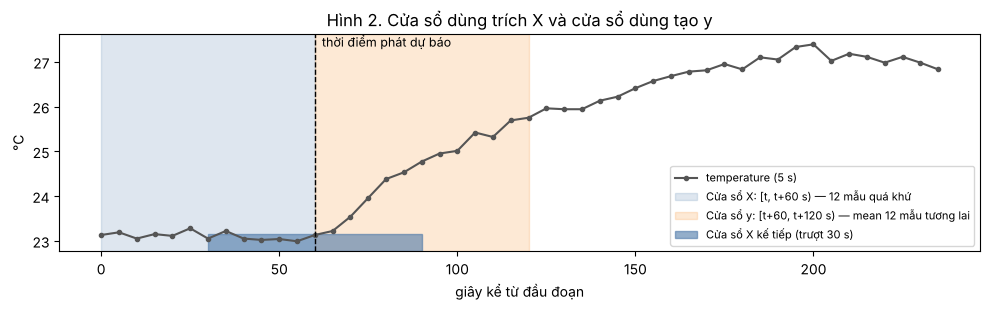

In [4]:
# Ô 4 — TODO 1: kích thước cửa sổ và bước trượt
WINDOW_SECONDS = 60                    # TODO 1
N = WINDOW_SECONDS // SAMPLE_S         # 60 / 5 = 12 mẫu: 0, 5, ..., 55 s
STEP_SECONDS = 30
STEP = STEP_SECONDS // SAMPLE_S        # 6 mẫu
MAX_MISSING_X = int(np.floor(0.10 * N))  # khuyết > 10% thì loại -> tối đa 1 mẫu/kênh
assert N == 12 and STEP == 6 and MAX_MISSING_X == 1
print(f"N = {N}, STEP = {STEP}, mỗi cặp dùng {2 * N} ô (X: {N} quá khứ, y: {N} tương lai)")

# Hình 2 — phân biệt cửa sổ trích X và cửa sổ tạo y
seg0 = grid[grid["segment"] == grid["segment"].iloc[0]]
t = (seg0.index[:4 * N] - seg0.index[0]).total_seconds()
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(t, seg0["temperature"].iloc[:4 * N], "o-", ms=3, color="#555", label="temperature (5 s)")
ax.axvspan(0, 60, color="#4c78a8", alpha=0.18, label="Cửa sổ X: [t, t+60 s) — 12 mẫu quá khứ")
ax.axvspan(60, 120, color="#f58518", alpha=0.18, label="Cửa sổ y: [t+60, t+120 s) — mean 12 mẫu tương lai")
ax.axvspan(30, 90, ymin=0, ymax=0.08, color="#4c78a8", alpha=0.6, label="Cửa sổ X kế tiếp (trượt 30 s)")
ax.axvline(60, color="k", ls="--", lw=1)
ax.text(61, ax.get_ylim()[1], " thời điểm phát dự báo", va="top", fontsize=9)
ax.set_xlabel("giây kể từ đầu đoạn"); ax.set_ylabel("°C")
ax.set_title("Hình 2. Cửa sổ dùng trích X và cửa sổ dùng tạo y")
ax.legend(fontsize=8, loc="lower right"); fig.tight_layout()
fig.savefig(OUT_DIR / "hinh2_cua_so_X_y.png", dpi=150); plt.show()

Mốc chia (cut): 2026-10-20 08:42:00+07:00
Ô lưới train/test: 504 / 216
Số cặp train/test (trước lọc thiếu): 81 / 33
Khớp kiểm tra bộ mẫu: 504/216 dòng, 81/33 cặp


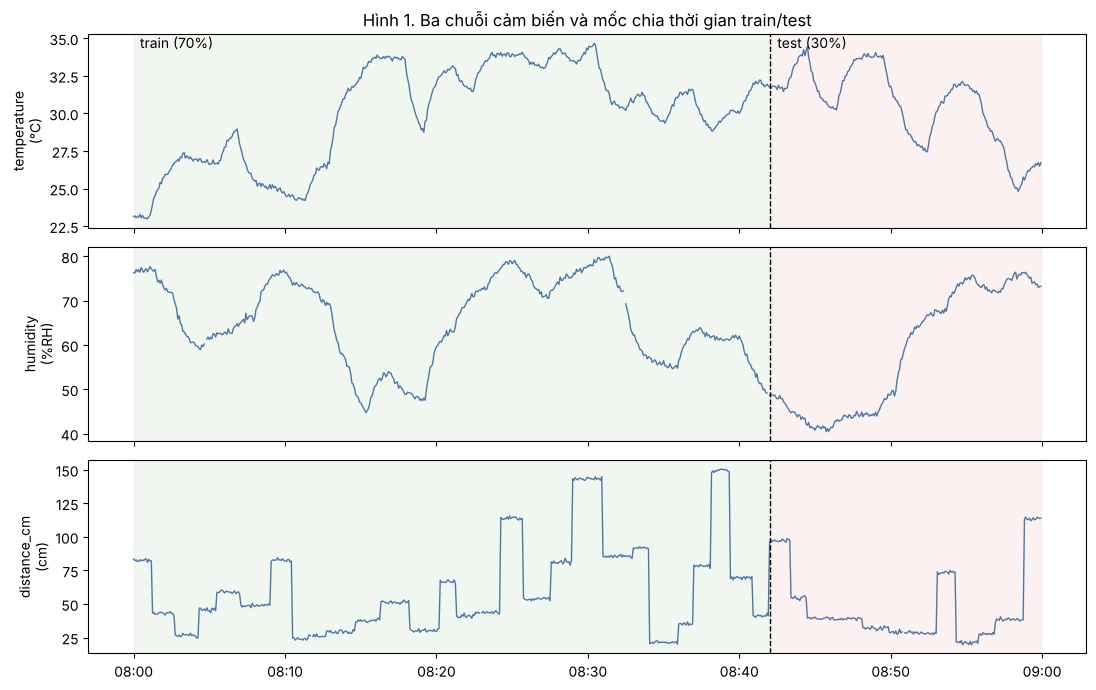

In [5]:
# Ô 5 — Chia theo thời gian (70/30) TRƯỚC khi tạo cặp, rồi tạo cặp riêng trong từng tập/đoạn
t_min = grid.index.min()
t_end = grid.index.max() + pd.Timedelta(seconds=SAMPLE_S)
raw_cut = t_min + 0.7 * (t_end - t_min)
cut = grid.index[grid.index >= raw_cut].min()      # mốc chia là một điểm lưới
train_grid, test_grid = grid[grid.index < cut], grid[grid.index >= cut]

def make_pairs(part: pd.DataFrame, split: str) -> list[dict]:
    pairs = []
    for seg_id, seg in part.groupby("segment"):
        for i in range(0, len(seg) - 2 * N + 1, STEP):
            xw, yw = seg.iloc[i:i + N], seg.iloc[i + N:i + 2 * N]
            pairs.append({"split": split, "segment": seg_id,
                          "input_start": xw.index[0], "input_end": xw.index[-1] + pd.Timedelta(seconds=SAMPLE_S),
                          "target_start": yw.index[0], "target_end": yw.index[-1] + pd.Timedelta(seconds=SAMPLE_S),
                          "X_window": xw[SENSORS].reset_index(drop=True),
                          "y_values": yw["temperature_label"].to_numpy()})
    return pairs

train_pairs, test_pairs = make_pairs(train_grid, "train"), make_pairs(test_grid, "test")
print(f"Mốc chia (cut): {cut.tz_convert(TZ)}")
print(f"Ô lưới train/test: {len(train_grid)} / {len(test_grid)}")
print(f"Số cặp train/test (trước lọc thiếu): {len(train_pairs)} / {len(test_pairs)}")
assert max(p["target_end"] for p in train_pairs) <= cut
assert min(p["input_start"] for p in test_pairs) >= cut
if len(grid) == 720 and grid["segment"].nunique() == 1:     # kiểm tra với bộ mẫu
    assert (len(train_grid), len(test_grid), len(train_pairs), len(test_pairs)) == (504, 216, 81, 33)
    print("Khớp kiểm tra bộ mẫu: 504/216 dòng, 81/33 cặp")

# Hình 1 — ba chuỗi cảm biến và mốc chia train/test
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
x_local = grid.index.tz_convert(TZ)
for ax, c in zip(axes, SENSORS):
    ax.plot(x_local, grid[c], lw=1, color="#4c78a8")
    ax.axvspan(x_local[0], cut.tz_convert(TZ), color="#54a24b", alpha=0.08)
    ax.axvspan(cut.tz_convert(TZ), x_local[-1], color="#e45756", alpha=0.08)
    ax.axvline(cut.tz_convert(TZ), color="k", ls="--", lw=1)
    ax.set_ylabel(f"{c}\n({UNITS[c]})")
axes[0].text(x_local[5], axes[0].get_ylim()[1], "train (70%)", va="top")
axes[0].text(cut.tz_convert(TZ), axes[0].get_ylim()[1], "  test (30%)", va="top")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=TZ))
axes[0].set_title("Hình 1. Ba chuỗi cảm biến và mốc chia thời gian train/test")
fig.tight_layout(); fig.savefig(OUT_DIR / "hinh1_ba_chuoi_moc_chia.png", dpi=150); plt.show()

**Trả lời:** Không được dùng mean nhiệt độ của chính phút tương lai làm một cột X. Tại thời điểm phát dự báo
(cuối cửa sổ X, t+60 s) hệ thống mới chỉ có 12 mẫu của [t, t+60 s) cho cả ba kênh. 12 nhiệt độ của
[t+60, t+120 s) chỉ xuất hiện sau khi phút đó kết thúc, nên chúng chỉ được dùng để *chấm* dự báo (tạo y).
Đưa giá trị đó vào X là rò rỉ dữ liệu: mô hình "chép đáp án", điểm test đẹp nhưng không dự báo được khi chạy thật.

## VII. Trích xuất đặc trưng

In [6]:
# Ô 6 — Hàm đặc trưng cho một kênh trong một cửa sổ
FEATURE_NAMES = ["mean", "std", "min", "max", "range", "delta", "slope"]

def channel_features(x, t_s, prefix: str) -> dict:
    x = np.asarray(x, dtype=float)
    t_s = np.asarray(t_s, dtype=float)
    return {
        f"{prefix}_mean": float(np.mean(x)),                    # TODO 2
        f"{prefix}_std": float(np.std(x, ddof=0)),              # TODO 2 (ddof=0, khác mặc định pandas)
        f"{prefix}_min": float(np.min(x)),
        f"{prefix}_max": float(np.max(x)),
        f"{prefix}_range": float(np.ptp(x)),
        f"{prefix}_delta": float(x[-1] - x[0]),                 # TODO 3
        f"{prefix}_slope": float(np.polyfit(t_s, x, 1)[0]),     # TODO 3 (đơn vị/giây)
    }

f = channel_features([1, 2, 3, 4], [0, 5, 10, 15], "x")
assert np.isclose(f["x_mean"], 2.5)
assert np.isclose(f["x_std"], 1.1180, atol=1e-4)
assert (f["x_min"], f["x_max"], f["x_range"], f["x_delta"]) == (1, 4, 3, 3)
assert np.isclose(f["x_slope"], 0.2)
print({k: round(v, 4) for k, v in f.items()})

{'x_mean': 2.5, 'x_std': 1.118, 'x_min': 1.0, 'x_max': 4.0, 'x_range': 3.0, 'x_delta': 3.0, 'x_slope': 0.2}


**Tính tay với x = [1, 2, 3, 4], t = [0, 5, 10, 15] s**

- mean = (1+2+3+4)/4 = **2,5**
- std (ddof=0) = √[((−1,5)² + (−0,5)² + 0,5² + 1,5²)/4] = √(5/4) = √1,25 ≈ **1,1180**
- min = 1; max = 4; range = 4 − 1 = **3**; delta = x[−1] − x[0] = 4 − 1 = **3**
- slope = Σ(t−t̄)(x−x̄) / Σ(t−t̄)², với t̄ = 7,5: tử = (−7,5)(−1,5)+(−2,5)(−0,5)+(2,5)(0,5)+(7,5)(1,5) = 25;
  mẫu = 56,25+6,25+6,25+56,25 = 125 → slope = 25/125 = **0,2 đơn vị/giây**

delta chỉ dùng 2 điểm đầu-cuối (đơn vị của kênh, vd °C) nên nhạy với nhiễu ở hai mép; slope dùng cả 12 điểm
(đơn vị kênh/giây, vd °C/s) nên ổn định hơn. Với cửa sổ đều 55 s giữa mẫu đầu và cuối, delta ≈ 55 × slope khi chuỗi gần tuyến tính.

In [7]:
# Ô 7 — Tạo bảng đặc trưng (21 cột X + y) cho train và test
T_S = np.arange(N) * SAMPLE_S
FEATURES = [f"{c}_{n}" for c in SENSORS for n in FEATURE_NAMES]
assert len(FEATURES) == 21

def fill_window(s: pd.Series) -> pd.Series:
    # nội suy tuyến tính chỉ trong cửa sổ đã hoàn tất; mép dùng giá trị gần nhất
    return s.interpolate(limit_area="inside").bfill().ffill()

def build_table(pairs: list[dict]) -> tuple[pd.DataFrame, dict]:
    rows, dropped = [], {"X_khuyet_qua_10%": 0, "y_thieu_nhiet_do_goc": 0}
    for p in pairs:
        if len(p["y_values"]) != N or np.isnan(p["y_values"]).any():
            dropped["y_thieu_nhiet_do_goc"] += 1          # không nội suy nhãn
            continue
        if (p["X_window"].isna().sum() > MAX_MISSING_X).any():
            dropped["X_khuyet_qua_10%"] += 1
            continue
        feats = {}
        for c in SENSORS:
            feats.update(channel_features(fill_window(p["X_window"][c]), T_S, c))
        rows.append({k: p[k] for k in ["split", "segment", "input_start", "input_end",
                                       "target_start", "target_end"]} | feats | {"y": p["y_values"].mean()})
    return pd.DataFrame(rows), dropped

train, drop_train = build_table(train_pairs)
test, drop_test = build_table(test_pairs)
assert len(train) and len(test), f"Không đủ cặp hợp lệ: train {drop_train}, test {drop_test}"
assert train["target_end"].max() <= cut
assert test["input_start"].min() >= cut
X_train, y_train = train[FEATURES], train["y"]
X_test, y_test = test[FEATURES], test["y"]
print(f"Cặp hợp lệ train/test: {len(train)} / {len(test)}")
print("Loại train:", drop_train, "| loại test:", drop_test)

def export_table(t: pd.DataFrame, path: Path) -> None:
    out = t.copy()
    for c in ["input_start", "input_end", "target_start", "target_end"]:
        out[c] = out[c].dt.tz_convert(TZ).dt.strftime("%Y-%m-%dT%H:%M:%S%z")
    out.round(6).to_csv(path, index=False)

export_table(train, OUT_DIR / "dac_trung_train.csv")
export_table(test, OUT_DIR / "dac_trung_test.csv")
preview = train[["input_start", "target_end", *FEATURES[:7], "y"]].head(3).copy()
for c in ["input_start", "target_end"]:
    preview[c] = preview[c].dt.tz_convert(TZ).dt.strftime("%H:%M:%S")
preview.round(4)

Cặp hợp lệ train/test: 81 / 33
Loại train: {'X_khuyet_qua_10%': 0, 'y_thieu_nhiet_do_goc': 0} | loại test: {'X_khuyet_qua_10%': 0, 'y_thieu_nhiet_do_goc': 0}


,input_start,target_end,temperature_mean,temperature_std,temperature_min,temperature_max,temperature_range,temperature_delta,temperature_slope,y
0,08:00:00,08:02:00,23.1067,0.0854,22.99,23.28,0.29,-0.14,-0.0024,24.4933
1,08:00:30,08:02:30,23.4275,0.5312,22.99,24.53,1.54,1.48,0.0254,25.5917
2,08:01:00,08:03:00,24.4933,0.8273,23.13,25.69,2.56,2.56,0.0471,26.3450


## VIII. Lựa chọn đặc trưng và học

In [8]:
# Ô 8 — TODO 4: SelectKBest(f_regression, k=6) trong Pipeline, chỉ fit trên train
K = 6          # đặt trước khi xem test, không chỉnh lại
ALPHA = 1.0
model6 = Pipeline([
    ("scaler", StandardScaler()),
    ("selector", SelectKBest(f_regression, k=K)),   # TODO 4
    ("model", Ridge(alpha=ALPHA)),
])
model6.fit(X_train, y_train)
prediction = model6.predict(X_test)

model21 = Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=ALPHA))])
model21.fit(X_train, y_train)

selector = model6.named_steps["selector"]
SELECTED = [FEATURES[i] for i in selector.get_support(indices=True)]
ranking = (pd.DataFrame({"feature": FEATURES, "F_score": selector.scores_, "p_value": selector.pvalues_,
                         "selected": selector.get_support()})
           .sort_values("F_score", ascending=False).reset_index(drop=True))
ranking.index += 1
ranking.to_csv(OUT_DIR / "xep_hang_dac_trung.csv", index_label="rank")
coef = pd.Series(model6.named_steps["model"].coef_, index=SELECTED)
print("6 cột được chọn:", SELECTED)
print("Hệ số Ridge_6 (trên thang chuẩn hoá):", coef.round(3).to_dict())
ranking.round({"F_score": 2, "p_value": 6})

6 cột được chọn: ['temperature_mean', 'temperature_min', 'temperature_max', 'temperature_delta', 'temperature_slope', 'humidity_min']
Hệ số Ridge_6 (trên thang chuẩn hoá): {'temperature_mean': 0.301, 'temperature_min': 1.144, 'temperature_max': 1.447, 'temperature_delta': 0.777, 'temperature_slope': 0.064, 'humidity_min': -0.015}


,feature,F_score,p_value,selected
1,temperature_mean,407.74,0.000000,True
2,temperature_max,399.14,0.000000,True
3,temperature_min,365.84,0.000000,True
4,humidity_min,2.50,0.117589,True
5,temperature_delta,2.25,0.137857,True
6,temperature_slope,2.13,0.147965,True
7,humidity_mean,2.05,0.156042,False
8,humidity_std,1.99,0.162609,False
9,distance_cm_max,1.85,0.178150,False
10,distance_cm_mean,1.84,0.178362,False


## IX. Đánh giá và giải thích kết quả

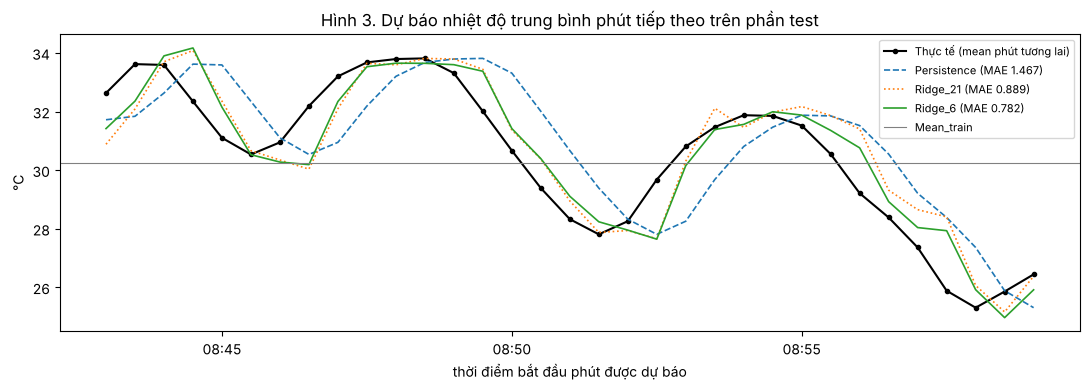

,MAE (°C),RMSE (°C),số cột X
Mean_train,2.1615,2.5197,0
Persistence,1.4665,1.6809,1
Ridge_21,0.8891,1.1332,21
Ridge_6,0.7823,0.9773,6


In [9]:
# Ô 9 — TODO 5: MAE, RMSE cho 4 cấu hình trên phần thời gian test
def mae(y, p):
    return float(np.mean(np.abs(np.asarray(y) - np.asarray(p))))           # TODO 5

def rmse(y, p):
    return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(p)) ** 2)))  # TODO 5

preds = {
    "Mean_train": np.full(len(test), y_train.mean()),
    "Persistence": test["temperature_mean"].to_numpy(),
    "Ridge_21": model21.predict(X_test),
    "Ridge_6": prediction,
}
for name, p in preds.items():   # đối chiếu với sklearn
    assert np.isclose(mae(y_test, p), mean_absolute_error(y_test, p))
    assert np.isclose(rmse(y_test, p), np.sqrt(mean_squared_error(y_test, p)))

errors = pd.DataFrame({name: {"MAE (°C)": mae(y_test, p), "RMSE (°C)": rmse(y_test, p)}
                       for name, p in preds.items()}).T
errors["số cột X"] = [0, 1, 21, K]
errors.round(4).to_csv(OUT_DIR / "bang_loi.csv", index_label="cau_hinh")

forecast_df = pd.DataFrame({"target_start": test["target_start"].dt.tz_convert(TZ),
                            "y_true": y_test.to_numpy(), **{k: np.asarray(v) for k, v in preds.items()}})
forecast_df.assign(target_start=forecast_df["target_start"].dt.strftime("%Y-%m-%dT%H:%M:%S%z")).round(4) \
    .to_csv(OUT_DIR / "du_bao_test.csv", index=False)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(forecast_df["target_start"], forecast_df["y_true"], "k.-", lw=1.5, label="Thực tế (mean phút tương lai)")
for name, style in [("Persistence", "--"), ("Ridge_21", ":"), ("Ridge_6", "-")]:
    ax.plot(forecast_df["target_start"], forecast_df[name], style, lw=1.2,
            label=f"{name} (MAE {errors.loc[name, 'MAE (°C)']:.3f})")
ax.axhline(y_train.mean(), color="grey", lw=0.8, label="Mean_train")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=TZ))
ax.set_xlabel("thời điểm bắt đầu phút được dự báo"); ax.set_ylabel("°C")
ax.set_title("Hình 3. Dự báo nhiệt độ trung bình phút tiếp theo trên phần test")
ax.legend(fontsize=8); fig.tight_layout()
fig.savefig(OUT_DIR / "hinh3_du_bao_test.png", dpi=150); plt.show()
errors.round(4)

In [10]:
# Ô 10 — Suy luận một cửa sổ vừa hoàn tất và lưu đầu ra
# Lấy cửa sổ 60 s gần nhất (trong một đoạn liên tục) thoả điều kiện khuyết <= 10%
window = None
for seg_id in grid["segment"].unique()[::-1]:
    seg = grid[grid["segment"] == seg_id]
    for end_i in range(len(seg), N - 1, -1):
        cand = seg.iloc[end_i - N:end_i]
        if (cand[SENSORS].isna().sum() <= MAX_MISSING_X).all():
            window = cand[SENSORS].reset_index(drop=True)
            window_start = cand.index[0]
            issued_at = cand.index[-1] + pd.Timedelta(seconds=SAMPLE_S)   # cửa sổ X đã hoàn tất
            break
    if window is not None:
        break
assert window is not None, "Không có cửa sổ 60 s nào đủ dữ liệu"

t0 = time.perf_counter()
x_new = {}
for c in SENSORS:
    x_new.update(channel_features(fill_window(window[c]), T_S, c))
y_hat = float(model6.predict(pd.DataFrame([x_new])[FEATURES])[0])
compute_ms = (time.perf_counter() - t0) * 1000

forecast_payload = {   # KHÔNG dùng khoá "temperature" (telemetry gốc)
    "temperature_forecast_next60s": round(y_hat, 2),
    "forecast_issued_at": issued_at.tz_convert(TZ).isoformat(),
    "input_window": [window_start.tz_convert(TZ).isoformat(), issued_at.tz_convert(TZ).isoformat()],
    "forecast_window": [issued_at.tz_convert(TZ).isoformat(),
                        (issued_at + pd.Timedelta(seconds=WINDOW_SECONDS)).tz_convert(TZ).isoformat()],
    "model": "Ridge_6",
}
print(json.dumps(forecast_payload, ensure_ascii=False, indent=2))
print(f"Nhiệt độ hiện tại (mẫu cuối): {window['temperature'].iloc[-1]:.2f} °C | thời gian tính: {compute_ms:.2f} ms")
print("Nhãn thật của phút này chỉ có sau", forecast_payload["forecast_window"][1])

joblib.dump({"model": model6, "features": FEATURES, "selected": SELECTED, "sensors": SENSORS,
             "window_seconds": WINDOW_SECONDS, "sample_s": SAMPLE_S, "max_missing_x": MAX_MISSING_X,
             "data_path": DATA_PATH, "data_note": DATA_NOTE}, OUT_DIR / "model_ridge6.joblib")

summary = {
    "data_path": DATA_PATH, "data_note": DATA_NOTE, "time_format": TIME_FORMAT,
    "device_id": str(devices[0]), "data_source": df["data_source"].unique().tolist(),
    "rows_in": n_rows_in, "duplicates": n_dup, "rows_after_check": len(df),
    "missing_after_check": {c: int(v) for c, v in missing_after.items()},
    "out_of_range_set_nan": out_of_range,
    "segments": int(grid["segment"].nunique()),
    "time_start": df["ts"].min().tz_convert(TZ).isoformat(), "time_end": df["ts"].max().tz_convert(TZ).isoformat(),
    "window_seconds": WINDOW_SECONDS, "N": N, "step": STEP, "cut": cut.tz_convert(TZ).isoformat(),
    "pairs_before_filter": {"train": len(train_pairs), "test": len(test_pairs)},
    "pairs_valid": {"train": len(train), "test": len(test)},
    "dropped": {"train": drop_train, "test": drop_test},
    "features": FEATURES, "k": K, "alpha": ALPHA, "selected_features": SELECTED,
    "metrics": errors[["MAE (°C)", "RMSE (°C)"]].round(4).to_dict(orient="index"),
    "example_forecast": forecast_payload, "compute_ms": round(compute_ms, 3),
}
(OUT_DIR / "tom_tat.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
print("Đã lưu:", sorted(p.name for p in OUT_DIR.iterdir()))

{
  "temperature_forecast_next60s": 27.22,
  "forecast_issued_at": "2026-10-20T09:00:00+07:00",
  "input_window": [
    "2026-10-20T08:59:00+07:00",
    "2026-10-20T09:00:00+07:00"
  ],
  "forecast_window": [
    "2026-10-20T09:00:00+07:00",
    "2026-10-20T09:01:00+07:00"
  ],
  "model": "Ridge_6"
}
Nhiệt độ hiện tại (mẫu cuối): 26.73 °C | thời gian tính: 6.14 ms
Nhãn thật của phút này chỉ có sau 2026-10-20T09:01:00+07:00
Đã lưu: ['bang_loi.csv', 'dac_trung_test.csv', 'dac_trung_train.csv', 'du_bao_test.csv', 'hinh1_ba_chuoi_moc_chia.png', 'hinh2_cua_so_X_y.png', 'hinh3_du_bao_test.png', 'model_ridge6.joblib', 'tom_tat.json', 'xep_hang_dac_trung.csv']


In [11]:
# Phiếu kết quả (in từ số liệu vừa chạy — không sửa tay cho giống bộ mẫu)
print(f"Nguồn: {DATA_PATH} — {DATA_NOTE}")
print(f"Số dòng trước/sau kiểm tra: {n_rows_in} / {len(df)} | trùng: {n_dup}")
print("Thiếu mỗi kênh sau kiểm tra:", {c: int(v) for c, v in missing_after.items()})
print(f"Số đoạn liên tục: {grid['segment'].nunique()} | khoảng thời gian: "
      f"{df['ts'].min().tz_convert(TZ):%Y-%m-%d %H:%M:%S} -> {df['ts'].max().tz_convert(TZ):%H:%M:%S}")
print(f"N = {N}, bước = {STEP}, cut = {cut.tz_convert(TZ):%H:%M:%S}, cặp train/test = {len(train)}/{len(test)}")
print("6 cột chọn:", SELECTED)
print(errors[["MAE (°C)", "RMSE (°C)"]].round(4).to_string())
best = errors["MAE (°C)"].idxmin()
print(f"Ridge_6 {'tốt hơn' if errors.loc['Ridge_6','MAE (°C)'] < errors.loc['Persistence','MAE (°C)'] else 'KHÔNG tốt hơn'} "
      f"Persistence theo MAE; cấu hình có MAE nhỏ nhất: {best}")

Nguồn: du_lieu_mau_B2.csv — Bộ mẫu tạo bằng Python (bai3/tao_du_lieu_mau.py, seed=3), 720 dòng = 60 phút, chu kỳ 5 s, theo schema kế thừa Bài 2. KHÔNG phải dữ liệu tải từ ThingsBoard/MongoDB. Dùng để kiểm tra quy trình khi chưa xuất được du_lieu_B2.csv của nhóm.
Số dòng trước/sau kiểm tra: 720 / 720 | trùng: 0
Thiếu mỗi kênh sau kiểm tra: {'temperature': 0, 'humidity': 3, 'distance_cm': 3}
Số đoạn liên tục: 1 | khoảng thời gian: 2026-10-20 08:00:00 -> 08:59:55
N = 12, bước = 6, cut = 08:42:00, cặp train/test = 81/33
6 cột chọn: ['temperature_mean', 'temperature_min', 'temperature_max', 'temperature_delta', 'temperature_slope', 'humidity_min']
             MAE (°C)  RMSE (°C)
Mean_train     2.1615     2.5197
Persistence    1.4665     1.6809
Ridge_21       0.8891     1.1332
Ridge_6        0.7823     0.9773
Ridge_6 tốt hơn Persistence theo MAE; cấu hình có MAE nhỏ nhất: Ridge_6


## Nhận xét kết quả và câu hỏi bắt buộc

> Các số dưới đây là của lần chạy với **bộ mẫu Python** `du_lieu_mau_B2.csv`. Khi đổi `DATA_PATH` sang
> `du_lieu_B2.csv` của nhóm, chạy lại toàn bộ và cập nhật nhận xét theo số liệu mới (không sửa số cho giống mẫu).

**Đọc bảng xếp hạng (Ô 8).** SelectKBest chọn `temperature_mean`, `temperature_max`, `temperature_min`
(F ≈ 366–408, p ≈ 0) và ba cột điểm thấp `humidity_min`, `temperature_delta`, `temperature_slope` (F ≈ 2,1–2,5, p ≈ 0,12–0,15).

- `temperature_mean`/`min`/`max`: mức nhiệt của phút vừa qua; nhiệt độ thay đổi chậm nên mức hiện tại là thông tin
  mạnh nhất về mức phút sau. Ba cột này gần trùng thông tin (bộ lọc đơn biến không loại được trùng lặp).
- `temperature_delta` (°C) và `temperature_slope` (°C/s): xu hướng tăng/giảm. Điểm F đơn biến thấp vì tự chúng
  không nói lên *mức* nhiệt, nhưng trong Ridge_6 hệ số của delta dương lớn (≈ 0,78 trên thang chuẩn hoá): mô hình
  dùng xu hướng để "ngoại suy" nhiệt độ phút tới — đúng điều persistence không làm được.
- `humidity_min` lọt vào vì buộc phải lấy đủ k = 6; p ≈ 0,12 không có ý nghĩa thống kê và trong bộ mẫu độ ẩm được
  tạo độc lập với nhiệt độ, nên đây là lựa chọn ngẫu nhiên, không phải quan hệ vật lý. Điểm F không phải bằng chứng nhân quả.

**Nhận xét có số liệu (Ô 9).**
1. Ridge_6 có MAE 0,782 °C, RMSE 0,977 °C, tốt hơn Persistence (MAE 1,467 °C, RMSE 1,681 °C) khoảng 47% MAE.
   Trên Hình 3, đường Persistence luôn trễ khoảng một phút so với thực tế ở các đoạn tăng/giảm; Ridge bám sát hơn nhờ delta/slope.
2. Giảm từ 21 xuống 6 cột không làm lỗi tăng mà giảm nhẹ (Ridge_21: MAE 0,889, RMSE 1,133 °C). Với chỉ 81 cặp train,
   các cột độ ẩm/khoảng cách gần như nhiễu đối với nhiệt độ tương lai; bỏ chúng giảm phương sai. k = 6 và alpha = 1 được đặt
   trước, không chỉnh lại sau khi xem test.
3. Mean_train (MAE 2,162 °C) kém nhất vì bỏ qua hoàn toàn biến thiên cảm biến.

**Giới hạn.** Bộ mẫu được tạo bằng Python (quán tính bậc 1 + nhiễu Gauss) nên quan hệ "xu hướng → phút sau" được
cài sẵn; chỉ có một phép chia thời gian, 33 cặp test chồng lấn 50% (không độc lập). Kết quả không đủ để khẳng định
hiệu năng trên cảm biến thật, thiết bị khác hay cách thay đổi môi trường khác. Wokwi cũng là mô phỏng: DHT22 trên Wokwi
nhảy tức thời theo thanh trượt, nên với dữ liệu nhóm học máy có thể **không** vượt persistence.

---

**1. Ba kênh đến từ cảm biến/chân nào? Vai trò sequence, uptime_s?**
`temperature` và `humidity` từ DHT22 (DATA = GPIO15), `distance_cm` từ HC-SR04 (TRIG = GPIO5, ECHO = GPIO18) trên ESP32
DevKit V1 (Wokwi). `sequence` (firmware gửi `seq`) tăng 1 mỗi gói: khe hở = mất gói, giảm = ESP32 khởi động lại.
`uptime_s` (millis()/1000) giảm cũng báo reset. Hai khoá này chỉ dùng ngắt đoạn ở Ô 3, **không** đưa vào X.

**2. Bản ghi khác mẫu học máy? Vì sao 12 mẫu và thêm 12 giá trị tương lai?**
Một bản ghi là số đo tại một thời điểm (một dòng CSV). Một mẫu học máy là cặp (X, y): X = 21 đặc trưng tóm tắt
cửa sổ [t, t+60 s), y = mean nhiệt độ của [t+60, t+120 s). Chu kỳ 5 s nên 60 s chứa 60/5 = 12 mẫu (0, 5, …, 55 s);
y là trung bình của phút tiếp theo nên cần thêm 12 nhiệt độ quan sát hợp lệ — mỗi cặp dùng 24 ô lưới.

**3. Trích xuất khác lựa chọn? Đơn vị delta và slope?**
Trích xuất tạo cột mới từ chuỗi (3 kênh × 7 hàm = 21 cột). Lựa chọn giữ một tập con các cột đã có (6/21, SelectKBest).
delta = x[−1] − x[0], đơn vị của kênh (°C, %RH, cm), chỉ phụ thuộc 2 điểm mép. slope = hệ số góc hồi quy tuyến tính
theo thời gian, đơn vị kênh/giây (°C/s…), dùng cả 12 điểm nên ít nhạy nhiễu hơn.

**4. Vì sao chia theo thời gian, tạo cặp riêng, fit scaler/selector trên train? Một cách rò rỉ tương lai.**
Mục tiêu là dự báo tương lai, nên test phải nằm sau train. Các cửa sổ chồng lấn (trượt 30 s); chia ngẫu nhiên sẽ
đặt hai cửa sổ gần như giống nhau vào hai tập. Tạo cặp riêng từng tập để không cặp nào vắt qua mốc chia
(assert `target_end ≤ cut`, `input_start ≥ cut`). Scaler/selector học trung bình, độ lệch, điểm F; fit trên toàn bộ
dữ liệu sẽ dùng thông tin test. Ví dụ rò rỉ: dùng cột `temperature_z` của Bài 2 (chuẩn hoá bằng mean/std cả lịch sử),
hoặc nội suy X bằng giá trị của phút tương lai, hoặc đưa mean phút tương lai vào X.

**5. Ridge_6 có vượt persistence không?**
Có, trong lần chạy với bộ mẫu: MAE 0,782 °C so với 1,467 °C; RMSE 0,977 °C so với 1,681 °C. Kết luận chỉ đúng cho bộ
mẫu này và một phép chia thời gian.

**6. Có được ghi bộ mẫu là dữ liệu từ ThingsBoard? Vì sao chưa coi kết quả mô phỏng là hiệu năng thật?**
Không. Bộ mẫu do `tao_du_lieu_mau.py` sinh ra (`data_source = python_sample`); nhóm cũng không dùng ThingsBoard mà
MQTT → Mosquitto → MongoDB. Dữ liệu mô phỏng (Python hoặc Wokwi) không có trôi cảm biến, nhiễu thật, quán tính nhiệt của
phòng, mất gói do mạng thực…; một phép chia với cửa sổ chồng lấn cũng chưa đủ để tổng quát hoá.